In [1]:
#first step for me,Even if it’s a small step, it means a lot to me. 
#cell one
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

csv_path = Path.cwd() / "freMTPL2sev.csv"

# Prefer the local copy; fall back to OpenML
if csv_path.exists():
    df = pd.read_csv(csv_path, encoding="utf-8-sig")
    source = f"Local file: {csv_path.name}"
else:
    from sklearn.datasets import fetch_openml
    dataset = fetch_openml(data_id=41215, as_frame=True)
    df = dataset.frame.copy()
    source = f"OpenML ID {dataset.details.get('id')} ({dataset.details.get('name')})"

df["ClaimAmount"] = pd.to_numeric(df["ClaimAmount"], errors="coerce")

invalid = ~np.isfinite(df["ClaimAmount"]) | (df["ClaimAmount"] <= 0)

# Keep IDpol so claims can be traced or merged later
claims = df.loc[~invalid].reset_index(drop=True)
losses = claims["ClaimAmount"].astype(float)

if losses.empty:
    raise ValueError("No valid positive claim amounts were found.")

print("Source:", source)
print("Columns:", df.columns.tolist())
print(f"\nTotal Records: {len(df):,}")
print(f"Invalid or Non-Positive Records: {invalid.sum():,}")
print(f"Valid Claims for Analysis: {len(losses):,}")

# Extra data-quality checks
print(f"Unique policies: {claims['IDpol'].nunique():,}")
print(f"Claims on policies with more than one claim: "
      f"{claims['IDpol'].duplicated(keep=False).sum():,}")
top_share = losses.value_counts().head(5).sum() / len(losses)
print(f"Share of claims taking one of the 5 most frequent amounts: {100*top_share:.1f}%")

print("\nFirst Five Records:")
display(claims.head())

print("\nClaim Amount Statistics — Dataset Monetary Unit:")
display(
    losses.describe(percentiles=[0.50, 0.90, 0.95, 0.975, 0.99])
    .rename("ClaimAmount").to_frame().round(2)
)

Source: OpenML ID 41215 (freMTPL2sev)
Columns: ['IDpol', 'ClaimAmount']

Total Records: 26,639
Invalid or Non-Positive Records: 0
Valid Claims for Analysis: 26,639
Unique policies: 24,950
Claims on policies with more than one claim: 3,068
Share of claims taking one of the 5 most frequent amounts: 42.0%

First Five Records:


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00



Claim Amount Statistics — Dataset Monetary Unit:


,ClaimAmount
count,26639.00
mean,2278.54
std,29297.48
min,1.00
50%,1172.00
90%,2799.07
95%,4861.68
97.5%,8234.24
99%,16793.70
max,4075400.56



Shape of the Claim Distribution:


,Raw claims,log10(claims)
Skewness,109.56,-0.55
Excess Kurtosis,14389.63,3.34
Coefficient of Variation,12.86,NaN
Mean / Median,1.94,NaN


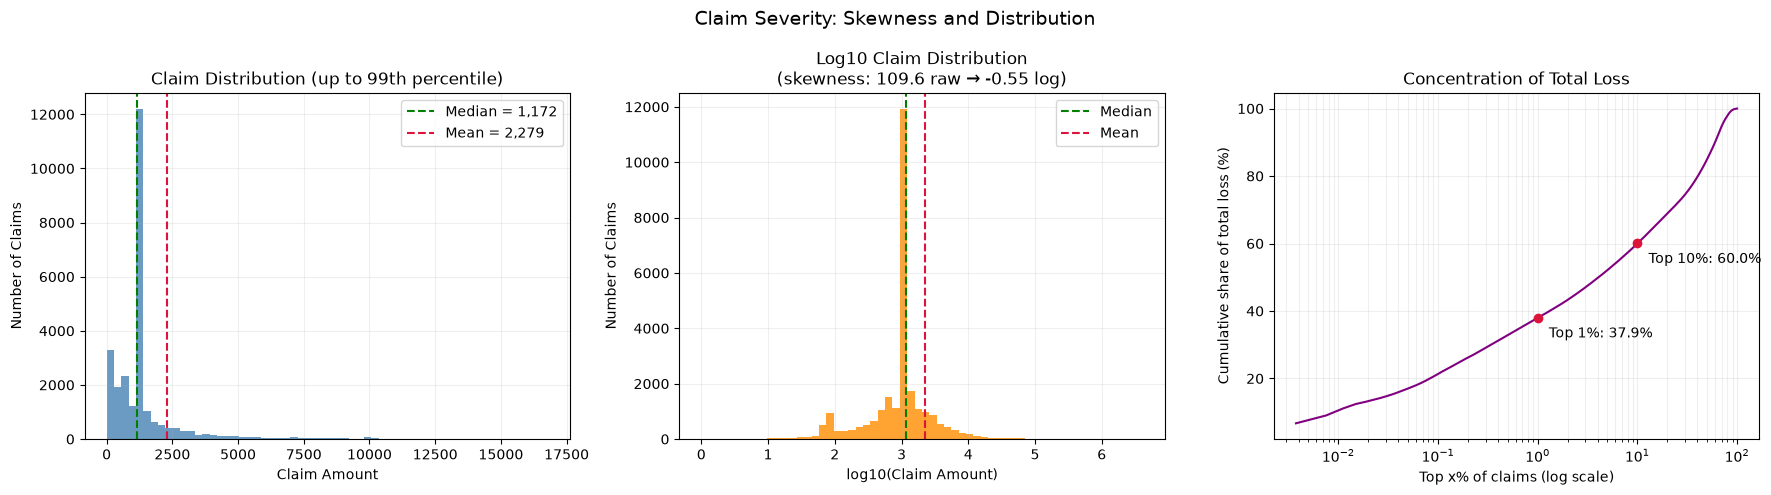

In [2]:
#cell two
# ---- Skewness and distribution ----
log_losses = np.log10(losses)
mean_, median_ = losses.mean(), losses.median()
p99 = losses.quantile(0.99)

stats = pd.DataFrame({
    "Raw claims": [losses.skew(), losses.kurt(), losses.std() / mean_, mean_ / median_],
    "log10(claims)": [log_losses.skew(), log_losses.kurt(), np.nan, np.nan],
}, index=["Skewness", "Excess Kurtosis", "Coefficient of Variation", "Mean / Median"])

print("\nShape of the Claim Distribution:")
display(stats.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: body of the distribution (up to the 99th percentile)
axes[0].hist(losses[losses <= p99], bins=60, color="steelblue", alpha=0.8)
axes[0].axvline(median_, color="green", linestyle="--", label=f"Median = {median_:,.0f}")
axes[0].axvline(mean_, color="crimson", linestyle="--", label=f"Mean = {mean_:,.0f}")
axes[0].set(title="Claim Distribution (up to 99th percentile)",
            xlabel="Claim Amount", ylabel="Number of Claims")
axes[0].legend(); axes[0].grid(alpha=0.2)

# Panel 2: log scale, where the full range becomes visible
axes[1].hist(log_losses, bins=60, color="darkorange", alpha=0.8)
axes[1].axvline(np.log10(median_), color="green", linestyle="--", label="Median")
axes[1].axvline(np.log10(mean_), color="crimson", linestyle="--", label="Mean")
axes[1].set(title=f"Log10 Claim Distribution\n(skewness: {losses.skew():.1f} raw → {log_losses.skew():.2f} log)",
            xlabel="log10(Claim Amount)", ylabel="Number of Claims")
axes[1].legend(); axes[1].grid(alpha=0.2)

# Panel 3: how concentrated total loss is in the largest claims
sorted_losses = np.sort(losses.to_numpy())[::-1]
cum_share = np.cumsum(sorted_losses) / sorted_losses.sum()
top_pct = np.arange(1, len(sorted_losses) + 1) / len(sorted_losses) * 100
axes[2].plot(top_pct, cum_share * 100, color="purple")
axes[2].set_xscale("log")
for p in [1, 10]:
    idx = int(len(sorted_losses) * p / 100) - 1
    axes[2].scatter(p, cum_share[idx] * 100, color="crimson", zorder=3)
    axes[2].annotate(f"Top {p}%: {cum_share[idx]*100:.1f}%", (p, cum_share[idx] * 100),
                     textcoords="offset points", xytext=(8, -14))
axes[2].set(title="Concentration of Total Loss",
            xlabel="Top x% of claims (log scale)", ylabel="Cumulative share of total loss (%)")
axes[2].grid(alpha=0.2, which="both")

fig.suptitle("Claim Severity: Skewness and Distribution", fontsize=14)
plt.tight_layout()
plt.show()

In [3]:
#cell three
# Retention in the same monetary unit as the claim amounts
R = 5000.0

gross = losses.to_numpy(dtype=float)
net = np.minimum(gross, R)
ceded = gross - net

def expected_shortfall(values, alpha):
    ordered = np.sort(np.asarray(values, dtype=float))[::-1]
    tail_size = len(ordered) * (1 - alpha)
    whole = int(np.floor(tail_size))
    fraction = tail_size - whole

    tail_sum = ordered[:whole].sum()
    if fraction > 0 and whole < len(ordered):
        tail_sum += fraction * ordered[whole]

    return tail_sum / tail_size

def risk_metrics(values):
    return {
        "Mean": np.mean(values),
        "Standard Deviation": np.std(values, ddof=1),
        "VaR 90%": np.quantile(values, 0.90),
        "VaR 95%": np.quantile(values, 0.95),
        "VaR 99%": np.quantile(values, 0.99),
        "ES 95%": expected_shortfall(values, 0.95),
        "ES 99%": expected_shortfall(values, 0.99),
        "Maximum": np.max(values),
    }

comparison = pd.DataFrame({
    "Gross Loss": risk_metrics(gross),
    "Net Loss": risk_metrics(net),
})
comparison.index.name = "Risk Metric"
comparison["Reduction (%)"] = 100 * (1 - comparison["Net Loss"] / comparison["Gross Loss"])

# Flag metrics that equal R by construction (cap is binding at that level)
p_exceed = np.mean(gross > R)

def capped_by_construction(metric):
    if metric == "Maximum":
        return True
    level = {"VaR 90%": 0.90, "VaR 95%": 0.95, "VaR 99%": 0.99,
             "ES 95%": 0.95, "ES 99%": 0.99}.get(metric)
    # VaR is exactly R once P(gross > R) > 1 - level; ES is near/at R in the same zone
    return level is not None and p_exceed > (1 - level)

comparison["Mechanical (capped at R)"] = [
    "yes" if capped_by_construction(m) else "" for m in comparison.index
]

assert np.allclose(gross, net + ceded), "Loss allocation check failed."

print("Contract: Per-claim XoL with unlimited reinsurance cover")
print(f"Retention: {R:,.2f}")
print("Amounts are expressed in the dataset's monetary unit.\n")
display(comparison.round(2))

print("\nRows marked 'yes' reflect the cap itself, not information from the data.")

# Layer-based metrics (these actually depend on the data)
n_trig = int((ceded > 0).sum())
print(f"\nNumber of Claims Triggering Cover: {n_trig:,}")
print(f"Claims Triggering Cover (%): {100 * n_trig / len(gross):.2f}")
print(f"Total Ceded Loss: {ceded.sum():,.2f}")
print(f"Ceded Share of Total Loss (%): {100 * ceded.sum() / gross.sum():.2f}")
print(f"Average Ceded Amount per Ceded Claim: {ceded[ceded > 0].mean():,.2f}")
print(f"Largest Single Claim's Share of Ceded Loss (%): {100 * ceded.max() / ceded.sum():.2f}")

print("\nNote: Metrics describe individual claim severity, not annual aggregate risk.")
print("Reinsurance premiums are not included.")

Contract: Per-claim XoL with unlimited reinsurance cover
Retention: 5,000.00
Amounts are expressed in the dataset's monetary unit.



,Gross Loss,Net Loss,Reduction (%),Mechanical (capped at R)
Risk Metric,,,,
Mean,2278.54,1341.00,41.15,
Standard Deviation,29297.48,1143.19,96.10,
VaR 90%,2799.07,2799.07,0.00,
VaR 95%,4861.68,4861.68,0.00,
VaR 99%,16793.70,5000.00,70.23,yes
ES 95%,23748.70,4997.92,78.95,
ES 99%,86445.82,5000.00,94.22,yes
Maximum,4075400.56,5000.00,99.88,yes



Rows marked 'yes' reflect the cap itself, not information from the data.

Number of Claims Triggering Cover: 1,250
Claims Triggering Cover (%): 4.69
Total Ceded Loss: 24,975,105.31
Ceded Share of Total Loss (%): 41.15
Average Ceded Amount per Ceded Claim: 19,980.08
Largest Single Claim's Share of Ceded Loss (%): 16.30

Note: Metrics describe individual claim severity, not annual aggregate risk.
Reinsurance premiums are not included.


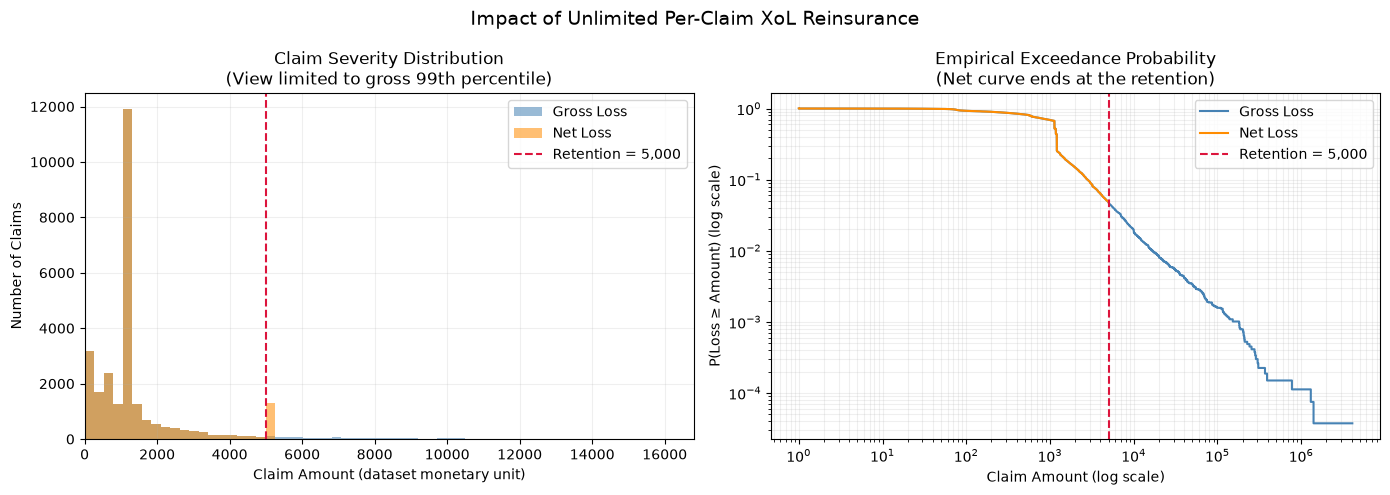

Chart saved as: xol_loss_distribution.png
Gross claims above the histogram range: 267
Largest gross claim (shown in right panel): 4,075,400.56


In [4]:
#cell four
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Histogram focused on the main body of the distribution
# Larger claims are omitted from this panel only, not from the analysis.
plot_limit = np.quantile(gross, 0.99)
bins = np.union1d(np.linspace(0, plot_limit, 65), [R])  # R is a bin edge
bins = bins[bins <= plot_limit]

axes[0].hist(gross, bins=bins, alpha=0.55, label="Gross Loss", color="steelblue")
axes[0].hist(net, bins=bins, alpha=0.55, label="Net Loss", color="darkorange")
axes[0].axvline(R, color="crimson", linestyle="--", label=f"Retention = {R:,.0f}")
axes[0].set(
    title="Claim Severity Distribution\n(View limited to gross 99th percentile)",
    xlabel="Claim Amount (dataset monetary unit)",
    ylabel="Number of Claims",
    xlim=(0, plot_limit)
)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Panel 2: Empirical exceedance probability P(Loss >= x), all valid claims.
# Using ">=" keeps the largest claim (its probability is 1/n, never zero).
def plot_exceedance(ax, values, label, color):
    amounts, counts = np.unique(values, return_counts=True)
    probability = 1 - (np.cumsum(counts) - counts) / len(values)
    ax.step(amounts, probability, where="pre", label=label, color=color)

plot_exceedance(axes[1], gross, "Gross Loss", "steelblue")
plot_exceedance(axes[1], net, "Net Loss", "darkorange")

axes[1].axvline(R, color="crimson", linestyle="--", label=f"Retention = {R:,.0f}")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set(
    title="Empirical Exceedance Probability\n(Net curve ends at the retention)",
    xlabel="Claim Amount (log scale)",
    ylabel="P(Loss ≥ Amount) (log scale)"
)
axes[1].legend()
axes[1].grid(alpha=0.2, which="both")

fig.suptitle("Impact of Unlimited Per-Claim XoL Reinsurance", fontsize=14)
plt.tight_layout()

fig.savefig("xol_loss_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved as: xol_loss_distribution.png")
print(f"Gross claims above the histogram range: {(gross > plot_limit).sum():,}")
print(f"Largest gross claim (shown in right panel): {gross.max():,.2f}")

In [5]:
#cell five
from pathlib import Path

retentions = [2500.0, 5000.0, 10000.0]
n = len(gross)
B = 1000  # bootstrap resamples

rows = []
for retention in retentions:
    scenario_net = np.minimum(gross, retention)
    scenario_ceded = gross - scenario_net
    triggered = scenario_ceded > 0

    # Bootstrap CI for ceded share (same seed -> same resamples across scenarios)
    rng = np.random.default_rng(42)
    boot = np.empty(B)
    for b in range(B):
        sample = gross[rng.integers(0, n, n)]
        boot[b] = 100 * np.maximum(sample - retention, 0).sum() / sample.sum()
    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

    rows.append({
        "Retention": retention,
        "Claims Triggering": int(triggered.sum()),
        "Claims Triggering (%)": 100 * triggered.mean(),
        "Ceded Loss Share (%)": 100 * scenario_ceded.sum() / gross.sum(),
        "Ceded Share 95% CI Low (%)": ci_low,
        "Ceded Share 95% CI High (%)": ci_high,
        "Mean Net Loss": scenario_net.mean(),
        "Net Std Dev": scenario_net.std(ddof=1),
        "Std Dev Reduction (%)": 100 * (1 - scenario_net.std(ddof=1) / gross.std(ddof=1)),
        "Avg Ceded per Ceded Claim": scenario_ceded[triggered].mean(),
        "Largest Claim Share of Ceded (%)": 100 * scenario_ceded.max() / scenario_ceded.sum(),
        "Total Ceded Loss": scenario_ceded.sum(),
    })

scenarios = pd.DataFrame(rows)

print("Sensitivity Analysis: Unlimited Per-Claim XoL")
print("Amounts are expressed in the dataset's monetary unit.")
print("Net VaR/ES at the 99% level are omitted: they equal the retention by construction.")
display(scenarios.round(2))

# Recompute baseline objects here so saved files never depend on stale cells
R_base = 5000.0
net_base = np.minimum(gross, R_base)
ceded_base = gross - net_base

output_dir = Path.cwd()

scenarios.to_csv(output_dir / "xol_scenarios.csv", index=False, encoding="utf-8-sig")
comparison.to_csv(output_dir / "xol_risk_comparison.csv", index=True, encoding="utf-8-sig")

allocation = pd.DataFrame({
    "Gross Loss": gross,
    "Net Loss": net_base,
    "Ceded Loss": ceded_base,
})
if "claims" in globals():  # present if IDpol was kept in the loading cell
    allocation.insert(0, "IDpol", claims["IDpol"].to_numpy())
allocation.to_csv(output_dir / "xol_claim_allocation.csv", index=False, encoding="utf-8-sig")

print(f"\nBaseline retention for claim allocation: {R_base:,.2f}")
print("Files saved in the working directory:")
print("- xol_scenarios.csv\n- xol_risk_comparison.csv\n- xol_claim_allocation.csv")
print("\nReinsurance premiums, capital costs, and counterparty risk are excluded.")

Sensitivity Analysis: Unlimited Per-Claim XoL
Amounts are expressed in the dataset's monetary unit.
Net VaR/ES at the 99% level are omitted: they equal the retention by construction.


,Retention,Claims Triggering,Claims Triggering (%),Ceded Loss Share (%),Ceded Share 95% CI Low (%),Ceded Share 95% CI High (%),Mean Net Loss,Net Std Dev,Std Dev Reduction (%),Avg Ceded per Ceded Claim,Largest Claim Share of Ceded (%),Total Ceded Loss
0,2500.0,3102,11.64,49.13,41.74,57.22,1159.04,680.65,97.68,9613.92,13.66,29822366.16
1,5000.0,1250,4.69,41.15,32.69,50.39,1341.00,1143.19,96.10,19980.08,16.30,24975105.31
2,10000.0,485,1.82,34.54,25.21,44.59,1491.56,1740.25,94.06,43225.35,19.39,20964296.30



Baseline retention for claim allocation: 5,000.00
Files saved in the working directory:
- xol_scenarios.csv
- xol_risk_comparison.csv
- xol_claim_allocation.csv

Reinsurance premiums, capital costs, and counterparty risk are excluded.


## Conclusion

**Data.** The analysis uses 26,639 claim amounts (24,950 policies). Severity is strongly right-skewed: mean 2,278.54 vs. median 1,172, standard deviation 29,297.48, and a maximum of 4,075,400.56. The largest 1% of claims account for 37.9% of total loss, and the largest 10% for 60.0%. About 42% of claims take one of only five amounts.

**Baseline contract (retention 5,000).** An unlimited per-claim XoL cover is triggered by 1,250 claims (4.69%) and cedes 24,975,105.31, or 41.15% of total loss. The standard deviation of retained loss falls from 29,297.48 to 1,143.19 (−96.10%), and the mean retained claim from 2,278.54 to 1,341.00.

**Interpretation of tail metrics.** Net VaR 99%, ES 99% and the maximum equal the retention by construction, because more than 1% of claims exceed it. The reductions of 70.23%, 94.22% and 99.88% therefore reflect the cap itself and are not evidence of reinsurance effectiveness. The informative measures are the ceded share, the number of triggering claims, the retained standard deviation and the average ceded amount per triggering claim.

**Sensitivity.** Raising the retention from 2,500 to 10,000 lowers the ceded share from 49.13% to 34.54%, raises the mean retained claim from 1,159.04 to 1,491.56, and increases the retained standard deviation from 680.65 to 1,740.25. The ordering of scenarios is deterministic, but the levels are uncertain: the 95% bootstrap interval for the ceded share at 5,000 is 32.69%–50.39%. The largest single claim accounts for 16.30% of ceded loss at 5,000 and 19.39% at 10,000, so results rely on very few extreme claims.

**Limitations.** The data contain severity only (no frequency, exposure, or time), so annual aggregate risk cannot be assessed. Cover is assumed unlimited, claims are treated as independent, and no event identifier exists. Reinsurance premiums, cost of capital, and counterparty risk are excluded. This analysis therefore does not identify an optimal retention.

**Next steps.** Merge with the frequency data (`freMTPL2freq`) for aggregate annual loss and burning cost, fit a tail model (e.g., GPD above a threshold) to stabilise high-layer estimates, test limited layers, and add reinsurance premium loadings to compare cost against risk reduction.